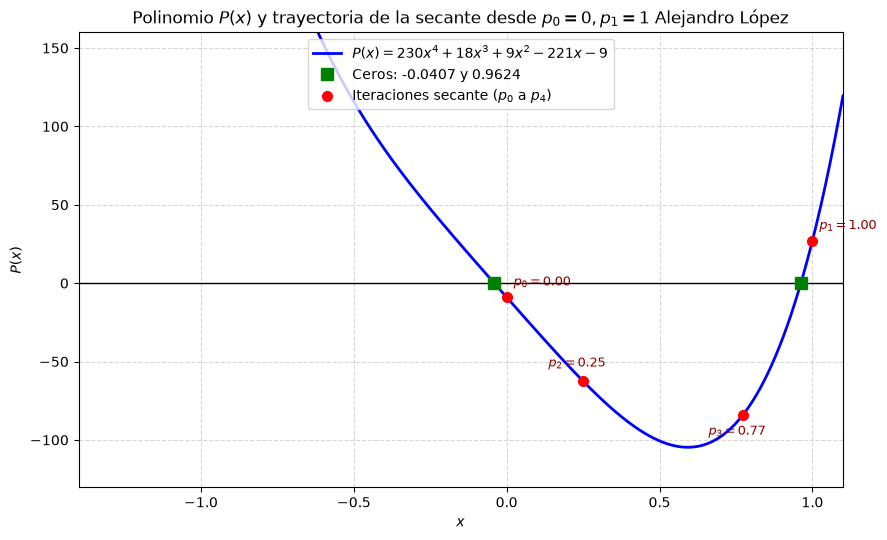

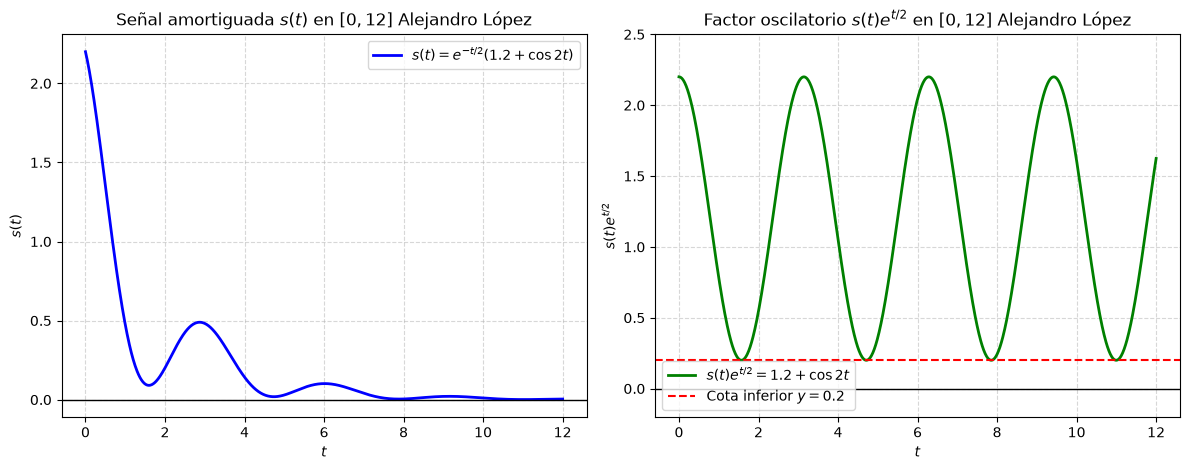

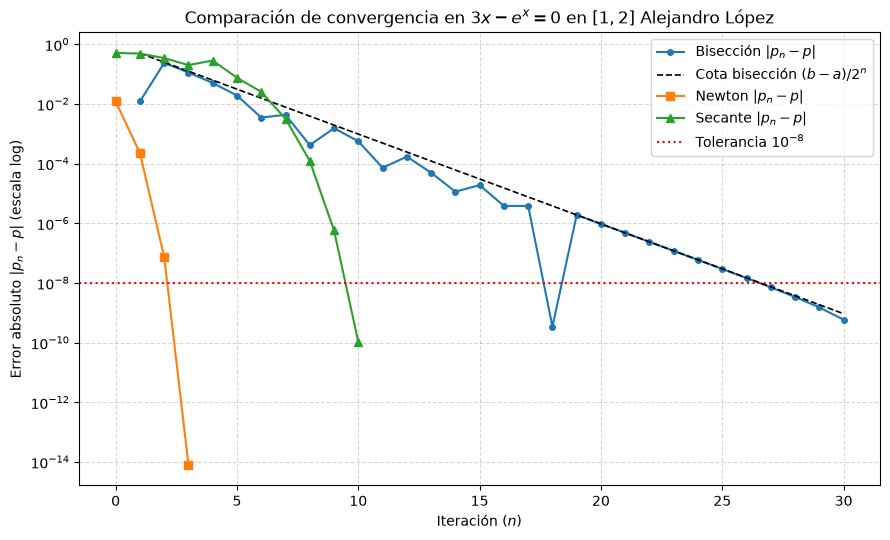

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def newton_raphson(f, df, p0, TOL=1e-6, N0=50, retornar_historia=False):
    historia = [p0]
    p_prev = p0
    for n in range(1, N0 + 1):
        df_val = df(p_prev)
        if df_val == 0:
            raise ZeroDivisionError("Derivada igual a cero.")
        p = p_prev - f(p_prev) / df_val
        historia.append(p)
        if abs(p - p_prev) < TOL:
            return (p, historia) if retornar_historia else p
        p_prev = p
    raise RuntimeError(f"El método de Newton no convergió en {N0} iteraciones.")

def secante(f, p0, p1, TOL=1e-6, N0=50, retornar_historia=False):
    historia = [p0, p1]
    q0, q1 = f(p0), f(p1)
    for n in range(2, N0 + 1):
        if q1 - q0 == 0:
            raise ZeroDivisionError("División por cero en la secante.")
        p = p1 - q1 * (p1 - p0) / (q1 - q0)
        historia.append(p)
        if abs(p - p1) < TOL:
            return (p, historia) if retornar_historia else p
        p0, q0 = p1, q1
        p1, q1 = p, f(p)
    raise RuntimeError(f"El método de la secante no convergió en {N0} iteraciones.")

def biseccion(f, a, b, N0=30):
    historia = []
    for _ in range(N0):
        p = (a + b) / 2.0
        historia.append(p)
        if f(a) * f(p) < 0:
            b = p
        else:
            a = p
    return historia

P = lambda x: 230*x**4 + 18*x**3 + 9*x**2 - 221*x - 9
dP = lambda x: 920*x**3 + 54*x**2 + 18*x - 221

r1 = secante(P, -0.5, 0.0, TOL=1e-10)
r2 = newton_raphson(P, dP, 1.0, TOL=1e-10)
_, hist_sec = secante(P, 0.0, 1.0, TOL=1e-6, retornar_historia=True)

x_vals = np.linspace(-1.4, 1.1, 1000)
plt.figure(figsize=(9, 5.5))
plt.plot(x_vals, P(x_vals), 'b-', linewidth=2, label='$P(x) = 230x^4 + 18x^3 + 9x^2 - 221x - 9$')
plt.axhline(0, color='black', linewidth=1)

plt.plot([r1, r2], [0, 0], 'gs', markersize=8, zorder=5, label=f'Ceros: {r1:.4f} y {r2:.4f}')

pts_p = hist_sec[:5]
plt.plot(pts_p, [P(pt) for pt in pts_p], 'ro', markersize=7, zorder=6, label='Iteraciones secante ($p_0$ a $p_4$)')
offsets = [(5, 8), (5, 8), (-25, 10), (-25, -15), (8, -5)]
for i, (pt, (dx, dy)) in enumerate(zip(pts_p, offsets)):
    plt.annotate(f'$p_{i}={pt:.2f}$', (pt, P(pt)), textcoords="offset points", xytext=(dx, dy),
                 fontsize=9, fontweight='bold', color='darkred')

plt.xlim(-1.4, 1.1)
plt.ylim(-130, 160)
plt.title('Polinomio $P(x)$ y trayectoria de la secante desde $p_0=0, p_1=1$ Alejandro López')
plt.xlabel('$x$')
plt.ylabel('$P(x)$')
plt.legend(loc='upper center')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('grafica_2_polinomio.png', dpi=300)
plt.show()

t = np.linspace(0, 12, 1000)
s = lambda t: 1.2 * np.exp(-t / 2) + np.exp(-t / 2) * np.cos(2 * t)
s_sin_amort = lambda t: 1.2 + np.cos(2 * t)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

ax1.plot(t, s(t), 'b-', linewidth=2, label='$s(t) = e^{-t/2}(1.2 + \\cos 2t)$')
ax1.axhline(0, color='black', linewidth=1)
ax1.set_title('Señal amortiguada $s(t)$ en $[0, 12]$ Alejandro López')
ax1.set_xlabel('$t$')
ax1.set_ylabel('$s(t)$')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(t, s_sin_amort(t), 'g-', linewidth=2, label='$s(t)e^{t/2} = 1.2 + \\cos 2t$')
ax2.axhline(0.2, color='red', linestyle='--', linewidth=1.5, label='Cota inferior $y = 0.2$')
ax2.axhline(0, color='black', linewidth=1)
ax2.set_ylim(-0.2, 2.5)
ax2.set_title('Factor oscilatorio $s(t)e^{t/2}$ en $[0, 12]$ Alejandro López')
ax2.set_xlabel('$t$')
ax2.set_ylabel('$s(t)e^{t/2}$')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('grafica_3_senal.png', dpi=300)
plt.show()

g = lambda x: 3*x - np.exp(x)
dg = lambda x: 3 - np.exp(x)

p_exacta = secante(g, 1.0, 2.0, TOL=1e-14)
hist_bis = biseccion(g, 1.0, 2.0, N0=30)
_, hist_newt = newton_raphson(g, dg, 1.5, TOL=1e-15, N0=20, retornar_historia=True)
_, hist_sec4 = secante(g, 1.0, 2.0, TOL=1e-15, N0=20, retornar_historia=True)

err_bis = [abs(pn - p_exacta) for pn in hist_bis if abs(pn - p_exacta) > 0]
err_newt = [abs(pn - p_exacta) for pn in hist_newt if abs(pn - p_exacta) > 0]
err_sec4 = [abs(pn - p_exacta) for pn in hist_sec4 if abs(pn - p_exacta) > 0]

n_bis = np.arange(1, len(err_bis) + 1)
cota_bis = (2.0 - 1.0) / (2.0 ** n_bis)

plt.figure(figsize=(9, 5.5))
plt.semilogy(n_bis, err_bis, 'o-', markersize=4, label='Bisección $|p_n - p|$')
plt.semilogy(n_bis, cota_bis, 'k--', linewidth=1.2, label='Cota bisección $(b-a)/2^n$')
plt.semilogy(np.arange(len(err_newt)), err_newt, 's-', markersize=6, label='Newton $|p_n - p|$')
plt.semilogy(np.arange(len(err_sec4)), err_sec4, '^-', markersize=6, label='Secante $|p_n - p|$')
plt.axhline(1e-8, color='red', linestyle=':', linewidth=1.5, label='Tolerancia $10^{-8}$')

plt.title('Comparación de convergencia en $3x - e^x = 0$ en $[1, 2]$ Alejandro López')
plt.xlabel('Iteración ($n$)')
plt.ylabel('Error absoluto $|p_n - p|$ (escala log)')
plt.legend(loc='upper right')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('grafica_4_convergencia.png', dpi=300)
plt.show()